In [1]:
import copy, numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
# Data: y = sin(x) + noise
rng = np.random.default_rng(2)
n = 200
x = rng.uniform(0, 6, n)
y = np.sin(x) + rng.normal(0, 0.3, n)
X = x.reshape(-1, 1)


X_tr, X_val, y_tr, y_val = train_test_split(X, y, train_size=140, random_state=1)

def to_t(a):
    return torch.tensor(a, dtype=torch.float32).reshape(len(a), -1)

X_tr_t, y_tr_t, X_val_t, y_val_t = to_t(X_tr), to_t(y_tr), to_t(X_val), to_t(y_val)

# A wide model: 100 hidden units
K, epochs, lr = 100, 10000, 0.003
torch.manual_seed(0)
model = nn.Sequential(nn.Linear(1, K), nn.Tanh(), nn.Linear(K, 1))
loss_fn = nn.MSELoss()
opt = torch.optim.Adam(model.parameters(), lr=lr)

best_val, best_epoch, best_state = np.inf, 0, None
for epoch in range(1, epochs + 1):
    opt.zero_grad()
    loss = loss_fn(model(X_tr_t), y_tr_t)
    loss.backward()
    opt.step()
    with torch.no_grad():
        val = loss_fn(model(X_val_t), y_val_t).item()
    # keep the weights with the lowest validation loss
    if val < best_val:                                  
        best_val, best_epoch = val, epoch
        best_state = copy.deepcopy(model.state_dict())

final_model = model                                     # weights after all epochs
best_model = nn.Sequential(nn.Linear(1, K), nn.Tanh(), nn.Linear(K, 1))
best_model.load_state_dict(best_state)

def predict(m, a):
    with torch.no_grad():
        return m(to_t(a)).numpy().ravel()

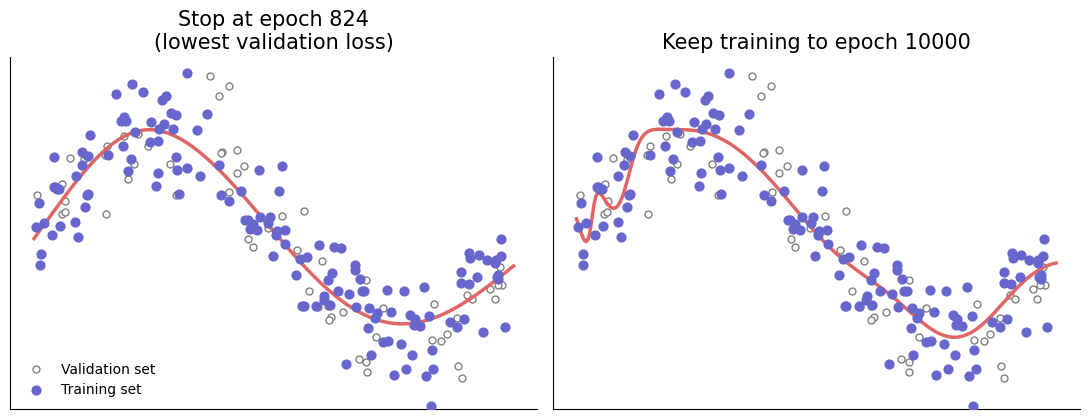

In [2]:
# Plot
BLUE, RED, GRAY = '#6666CC', '#E06666', 'gray'

grid = np.linspace(0, 6, 300).reshape(-1, 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.3), sharey=True)
for a, m, title in [(ax[0], best_model, f'Stop at epoch {best_epoch}\n(lowest validation loss)'),
                    (ax[1], final_model, f'Keep training to epoch {epochs}')]:
    a.scatter(X_val, y_val, s=25, color='white', edgecolor=GRAY, label='Validation set')
    a.scatter(X_tr, y_tr, s=40, color=BLUE, label='Training set', zorder=4)
    a.plot(grid, predict(m, grid), color=RED, lw=2.5, zorder=3)
    a.set_title(title, fontsize=15)
    a.set_xticks([]); a.set_yticks([]); a.set_ylim(-1.8, 1.8)
    for s in ['top', 'right']: a.spines[s].set_visible(False)
ax[0].legend(frameon=False, loc='lower left')
plt.tight_layout()
plt.show()

In [3]:
import numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

BLUE, RED, GRAY = '#6666CC', '#E06666', 'gray'

# Data: y = sin(x) + noise
rng = np.random.default_rng(2)
n = 200
x = rng.uniform(0, 6, n)
y = np.sin(x) + rng.normal(0, 0.3, n)
X = x.reshape(-1, 1)

# Training set (30 observations) and validation set (the rest)
X_tr, X_val, y_tr, y_val = train_test_split(X, y, train_size=140, random_state=1)

def to_t(a):
    return torch.tensor(a, dtype=torch.float32).reshape(len(a), -1)

X_tr_t, y_tr_t, X_val_t, y_val_t = to_t(X_tr), to_t(y_tr), to_t(X_val), to_t(y_val)

# A wide model: 100 hidden units
K, epochs, lr = 100, 10000, 0.003
torch.manual_seed(0)
model = nn.Sequential(nn.Linear(1, K), nn.Tanh(), nn.Linear(K, 1))
loss_fn = nn.MSELoss()
opt = torch.optim.Adam(model.parameters(), lr=lr)

loss_tr, loss_val = [], []
for epoch in range(epochs):
    opt.zero_grad()
    loss = loss_fn(model(X_tr_t), y_tr_t)
    loss.backward()
    opt.step()
    loss_tr.append(loss.item())
    with torch.no_grad():                       # validation loss is only recorded, not used to fit
        loss_val.append(loss_fn(model(X_val_t), y_val_t).item())

best = int(np.argmin(loss_val))

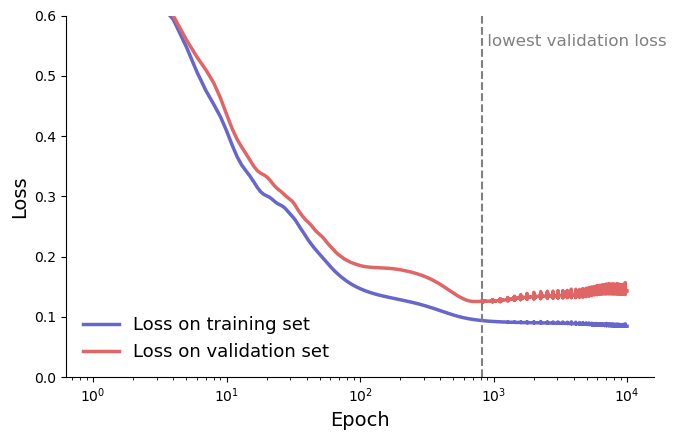

In [4]:
# Plot
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(range(1, epochs + 1), loss_tr, color=BLUE, lw=2.5, label='Loss on training set')
ax.plot(range(1, epochs + 1), loss_val, color=RED, lw=2.5, label='Loss on validation set')
ax.set_xscale('log')
ax.axvline(best + 1, color=GRAY, ls='--', lw=1.5)
ax.text(best + 1, 0.57, ' lowest validation loss', color=GRAY, fontsize=12, va='top')
ax.set_xlabel('Epoch', fontsize=14); ax.set_ylabel('Loss', fontsize=14)
ax.set_ylim(0, 0.6)
ax.legend(frameon=False, fontsize=13)
for s in ['top', 'right']: ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

In [5]:
# CV
import numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt

BLUE, RED, GRAY = '#6666CC', '#E06666', 'gray'

# Data: y = sin(x) + noise (a small data set: 40 observations)
rng = np.random.default_rng(2)
n = 200
x = rng.uniform(0, 6, n)
y = np.sin(x) + rng.normal(0, 0.3, n)
X = x.reshape(-1, 1)

def to_t(a):
    return torch.tensor(a, dtype=torch.float32).reshape(len(a), -1)


def new_model(seed=0):
    torch.manual_seed(seed)
    return nn.Sequential(nn.Linear(1, K), nn.Tanh(), nn.Linear(K, 1))

# 5-fold cross-validation: record the training and validation loss at every epoch
from sklearn.model_selection import KFold
K, epochs, lr, k = 100, 10000, 0.003, 5      # wide network: 100 hidden units
loss_fn = nn.MSELoss()
loss_tr = np.zeros((k, epochs)); loss_val = np.zeros((k, epochs))
folds = KFold(n_splits=k, shuffle=True, random_state=1).split(X)
for f, (tr, val) in enumerate(folds):
    X_tr, y_tr, X_val, y_val = to_t(X[tr]), to_t(y[tr]), to_t(X[val]), to_t(y[val])
    model = new_model()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for e in range(epochs):
        opt.zero_grad()
        loss = loss_fn(model(X_tr), y_tr)
        loss.backward()
        opt.step()
        loss_tr[f, e] = loss.item()
        with torch.no_grad():
            loss_val[f, e] = loss_fn(model(X_val), y_val).item()

# Cross-validation loss = average of the k validation losses at each epoch
cv_loss = loss_val.mean(axis=0)
best = int(np.argmin(cv_loss)) + 1           # epoch with the smallest cross-validation loss
print(f'Best epoch: {best} (CV loss {cv_loss[best - 1]:.3f}; at epoch {epochs}: {cv_loss[-1]:.3f})')

# Refit on ALL the data for the chosen number of epochs (and for all epochs, for comparison)
X_all, y_all = to_t(X), to_t(y)
def fit_all(n_epochs):
    model = new_model()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(n_epochs):
        opt.zero_grad()
        loss_fn(model(X_all), y_all).backward()
        opt.step()
    return model

model_best, model_last = fit_all(best), fit_all(epochs)

Best epoch: 1023 (CV loss 0.108; at epoch 10000: 0.116)


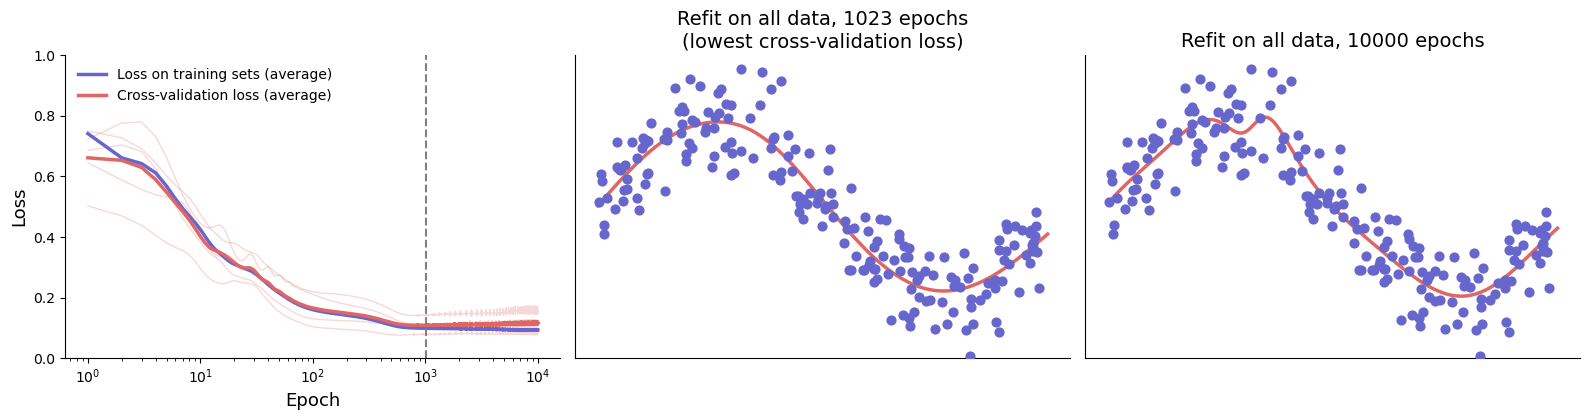

In [6]:

# Plot
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
a = ax[0]
for f in range(k):
    a.plot(range(1, epochs + 1), loss_val[f], color=RED, lw=1, alpha=0.25)
a.plot(range(1, epochs + 1), loss_tr.mean(axis=0), color=BLUE, lw=2.5, label='Loss on training sets (average)')
a.plot(range(1, epochs + 1), cv_loss, color=RED, lw=2.5, label='Cross-validation loss (average)')
a.axvline(best, color=GRAY, ls='--', lw=1.5)
a.set_xscale('log'); a.set_xlabel('Epoch', fontsize=13); a.set_ylabel('Loss', fontsize=13)
a.set_ylim(0, 1.0)
a.legend(frameon=True, facecolor='white', edgecolor='none', framealpha=1, fontsize=10, loc='upper left')

grid = np.linspace(0, 6, 300).reshape(-1, 1)
for a, m, title in [(ax[1], model_best, f'Refit on all data, {best} epochs\n(lowest cross-validation loss)'),
                    (ax[2], model_last, f'Refit on all data, {epochs} epochs')]:
    with torch.no_grad():
        a.plot(grid, m(to_t(grid)).numpy().ravel(), color=RED, lw=2.5, zorder=3)
    a.scatter(x, y, s=40, color=BLUE, zorder=4)
    a.set_title(title, fontsize=14)
    a.set_xticks([]); a.set_yticks([]); a.set_ylim(-1.8, 1.8)
for a in ax:
    for s in ['top', 'right']: a.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

In [7]:
import numpy as np, pandas as pd, torch, torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.linear_model import LogisticRegression

BLUE, RED, GRAY = '#6666CC', '#E06666', 'gray'

# Data
df = pd.read_csv('Heart_data.csv')
predictors = ['thalach', 'age', 'trestbps', 'chol', 'sex', 'angina', 'non_angina', 'asymptomatic']
X = df[predictors].values.astype(float)
y = df['diagnosis'].values.astype(float)

def to_t(a):
    return torch.tensor(a, dtype=torch.float32).reshape(len(a), -1)

K, epochs, lr, k = 100, 1000, 0.001, 5
loss_fn = nn.BCEWithLogitsLoss()
folds = list(StratifiedKFold(n_splits=k, shuffle=True, random_state=1).split(X, y))

loss_val = np.zeros((k, epochs))
p_nn = np.zeros((epochs, len(y)))            # out-of-fold probabilities of the network, at every epoch

for f, (tr, val) in enumerate(folds):
    # Normalization for stability
    mu, sd = X[tr].mean(axis=0), X[tr].std(axis=0)
    X_tr, X_val = (X[tr] - mu) / sd, (X[val] - mu) / sd
    X_tr_t, y_tr_t, X_val_t, y_val_t = to_t(X_tr), to_t(y[tr]), to_t(X_val), to_t(y[val])

    torch.manual_seed(0)
    model = nn.Sequential(nn.Linear(len(predictors), K), nn.ReLU(), nn.Linear(K, 1))
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for e in range(epochs):
        opt.zero_grad()
        loss_fn(model(X_tr_t), y_tr_t).backward()
        opt.step()
        with torch.no_grad():
            out = model(X_val_t)
            loss_val[f, e] = loss_fn(out, y_val_t).item()
            p_nn[e, val] = torch.sigmoid(out).numpy().ravel()

best = int(np.argmin(loss_val.mean(axis=0)))  # epoch with the smallest cross-validation loss
auc_nn = roc_auc_score(y, p_nn[best])
print(f'Best epoch {best + 1}: NN AUC = {auc_nn:.3f}')

/Users/hyeongjin/anaconda3/lib/python3.10/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


Best epoch 121: NN AUC = 0.856


In [8]:
import numpy as np
import statsmodels.formula.api as smf
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold

#X = df.drop(columns="diagnoisis").values   # 6 predictors
#y = df["diagnosis"].values                # 1 = diabetes

k = 5
formula = "diagnosis ~ thalach + age + trestbps + chol + sex + angina + non_angina + asymptomatic"
folds = list(StratifiedKFold(n_splits=k, shuffle=True, random_state=1).split(X, y))

aucs = []
p_lr = np.zeros(len(y))        
for _, (train_idx, valid_idx) in enumerate(folds):
    train, test = df.iloc[train_idx], df.iloc[valid_idx]
    fit = smf.logit(formula, data=train).fit(disp=0)
    p_lr[valid_idx] = fit.predict(test) 
    aucs.append(roc_auc_score(test["diagnosis"], p_lr[valid_idx]))

#print(f"CV AUC: {np.mean(aucs):.3f} ± {np.std(aucs):.3f}")

# ROC curve from the pooled out of fold predictions
auc_lr = roc_auc_score(y, p_lr)
fpr, tpr, _ = roc_curve(y, p_lr)

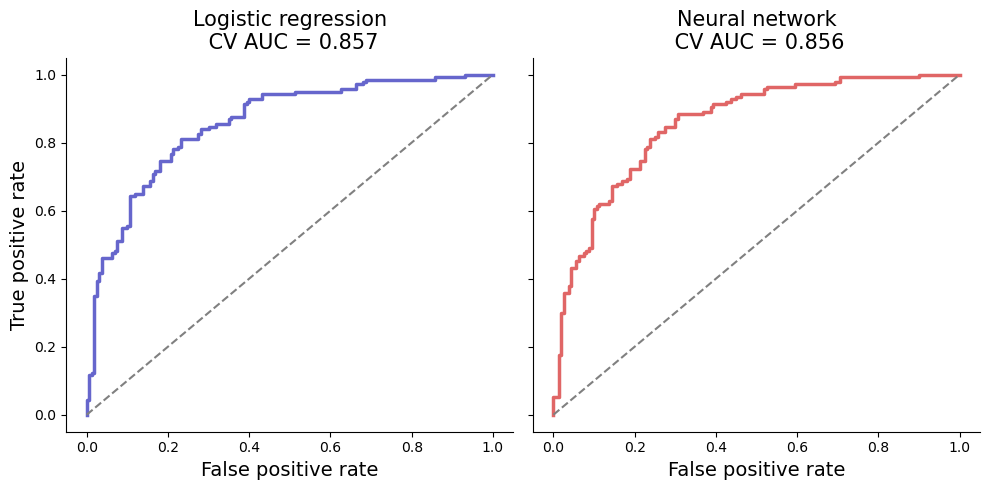

In [9]:
# ROC curves, drawn separately (every patient is predicted by a model that did not use that patient)
fig, ax = plt.subplots(1, 2, figsize=(10, 5), sharey=True)
for a, p, auc, color, title in [(ax[0], p_lr, auc_lr, BLUE, 'Logistic regression'),
                                (ax[1], p_nn[best], auc_nn, RED, 'Neural network')]:
    fpr, tpr, _ = roc_curve(y, p)
    a.plot(fpr, tpr, color=color, lw=2.5)
    a.plot([0, 1], [0, 1], color=GRAY, ls='--', lw=1.5)
    a.set_title(f'{title}\n CV AUC = {auc:.3f}', fontsize=15)
    a.set_xlabel('False positive rate', fontsize=14)
    for s in ['top', 'right']: a.spines[s].set_visible(False)
ax[0].set_ylabel('True positive rate', fontsize=14)
plt.tight_layout()
plt.show()